# Plot astrophysical factor angular dependence
This notebook describes how to generate a radial/angular profile of the astrophysical factor previously generated with `CLUMPY`.

Authors: Gonzalo Rodriguez Fernandez gonzalo.rodriguez.fernandez@roma2.infn.it, Michele Doro michele.doro@unipd.it

Last update: 2024.03.04

### General imports

In [34]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.offsetbox import AnchoredText
import pandas as pd
import numpy as np
import glob as glob
from scipy.interpolate import interp1d, make_interp_spline, BSpline

#### Definition of path and functions

In [35]:
# Define paths for astrophysical profiles
path_j = "../../clumpy/Jfactors/profile/"
path_d = "../../clumpy/Dfactors/profile/"
!ls -l {path_j}
!ls -l {path_d}

total 0
drwxr-xr-x  16 mdoro  staff  512 Jul 18 13:35 Burkert
drwxr-xr-x  16 mdoro  staff  512 Jul 18 13:35 Einasto
total 0
drwxr-xr-x  16 mdoro  staff  512 Jul 18 13:35 Burkert
drwxr-xr-x  16 mdoro  staff  512 Jul 18 13:35 Einasto


In [36]:
# Extract data from files with DM annihilation profiles
def jfactor_inter1d(name, profile):
    
    if (profile=="Einasto"):
        filename=path_j+profile+'/rvir_'+name+'_MCMC.dat.Jalphaint_cls.output'
    if (profile=="Burkert"):
        filename=path_j+profile+'/rvir_'+name+'_MCMC.dat.Jalphaint_cls.output'
        
    df_j = pd.read_csv(filename,
                sep='\s+',
                header=None,
                comment='#',
                names=['alpha','jfactor','d1','d2','d3','dw1s','up1s','dw2s','up2s'])

    return np.array([interp1d(df_j.alpha.values, df_j.jfactor.values, kind="quadratic"),
                     interp1d(df_j.alpha.values, df_j.dw1s.values, kind="quadratic"), 
                     interp1d(df_j.alpha.values, df_j.up1s.values, kind="quadratic")])

In [37]:
# Extract data from files with DM decay profiles
def dfactor_inter1d(name, profile):
       
    if (profile=="Einasto"):
        filename=path_d+profile+'/rvir_'+name+'_MCMC.dat.Dalphaint_cls.output'
    if (profile=="Burkert"):
        filename=path_d+profile+'/rvir_'+name+'_MCMC.dat.Dalphaint_cls.output'
            
    df_j = pd.read_csv(filename,
                sep='\s+',
                header=None,
                comment='#',
                names=['alpha','jfactor','d1','d2','d3','dw1s','up1s','dw2s','up2s'])

    return np.array([interp1d(df_j.alpha.values, df_j.jfactor.values, kind="quadratic"),
                     interp1d(df_j.alpha.values, df_j.dw1s.values, kind="quadratic"), 
                     interp1d(df_j.alpha.values, df_j.up1s.values, kind="quadratic")])

## DM annihilation profiles
In this section we plot the profiles for Einasto and Burkert DM annihilation models

#### Target name definition 

In [38]:
df_input = pd.read_csv('Density_dsph_parameters_14.csv')
# dSph names
dSphNames = df_input['dSphNames'].values 

# Other parameters
# - distance kpc
# - Rtidal_einasto: tidal radius according to Einasto profile in kpc
# - Rtidal_burkert: tidal radius according to Burkert profile in kpc
distance       = df_input['distance'].values 
Rtidal_einasto = df_input['Rtidal_einasto'].values 
Rtidal_burkert = df_input['Rtidal_burkert'].values 
alpha_opt      = df_input['alpha_opt'].values 
chi2_Einasto = df_input['chi2_Einasto'].values 
chi2_Burkert = df_input['chi2_Burkert'].values 
channels = ['b','Tau']

alpha_Einasto_tidal = np.rad2deg(np.arctan(np.divide(Rtidal_einasto,distance)))
alpha_Burkert_tidal = np.rad2deg(np.arctan(np.divide(Rtidal_burkert,distance)))


df_input.head(10)

,Unnamed: 0,dSphNames,distance,Rtidal_einasto,Rtidal_burkert,alpha_opt,chi2_Einasto,chi2_Burkert
0,0,BooI,65,5.10,15.10,0.81,1.000000,1.000000
1,1,CBe,42,6.30,19.00,0.20,1.467308,1.439623
2,2,DraI,75,4.83,4.30,0.23,1.391558,1.389849
3,3,GruII,53,0.35,9.50,0.36,1.000000,1.000000
4,4,RetII,32,1.70,5.80,0.15,1.954545,1.800000
5,5,Scl,84,2.95,3.71,0.29,1.348967,1.347935
6,6,Seg1,23,0.43,28.00,0.37,1.000000,1.000000
7,7,Sex,84,7.80,9.90,0.60,1.000000,1.000000
8,8,SgrI,59,1.56,1.70,6.91,1.000000,1.000000
9,9,SgrII,67,3.70,4.20,0.06,1.978571,1.860000


In [39]:
distance

array([65, 42, 75, 53, 32, 84, 23, 84, 59, 67, 30, 38, 78, 43])

In [40]:
print("Src    rt    J       J_LO      J_UP   RATIO/Wil1")
for src in dSphNames:
    print(f'{src:5s}',end=" ")
    rt = df_input['Rtidal_einasto'][dSphNames==src]
    rt = float(rt)
    if (rt>10): rt=10
    rt = 1.
    print(f'{rt:5.2f}', end=' ')
    jmedian = jfactor_inter1d(name=src, profile='Einasto')[0](rt)
    jup = jfactor_inter1d(name=src, profile='Einasto')[1](rt)
    jdown = jfactor_inter1d(name=src, profile='Einasto')[2](rt)
    print(f'{jmedian:.2e}',end=' ')
    print(f'{jdown:.2e}',end=' ')
    print(f'{jup:.2e}',end=' ')
    print(f'{jmedian/1.69e+19:5.2f}',end=' ')
    print()


Src    rt    J       J_LO      J_UP   RATIO/Wil1
BooI   1.00 5.57e+18 4.85e+19 1.63e+18  0.33 
CBe    1.00 5.98e+19 7.34e+20 9.79e+18  3.54 
DraI   1.00 5.49e+18 6.95e+18 4.61e+18  0.32 
GruII  1.00 2.38e+15 9.46e+16 9.43e+11  0.00 
RetII  1.00 1.64e+19 1.76e+20 3.04e+18  0.97 
Scl    1.00 2.64e+18 3.78e+18 2.18e+18  0.16 
Seg1   1.00 1.46e+17 4.33e+19 9.14e+14  0.01 
Sex    1.00 2.22e+18 3.55e+18 1.75e+18  0.13 
SgrI   1.00 8.15e+18 1.78e+19 8.89e+17  0.48 
SgrII  1.00 9.65e+18 9.25e+20 8.27e+17  0.57 
TriII  1.00 5.05e+16 1.79e+19 1.67e+12  0.00 
UMaII  1.00 1.29e+19 3.89e+19 5.87e+18  0.77 
UMi    1.00 4.16e+19 7.23e+19 2.47e+19  2.46 
Wil1   1.00 1.69e+19 1.10e+20 5.11e+18  1.00 


/var/folders/b4/206k7jy123760vx_14btyhlw0000gn/T/ipykernel_74183/4075960254.py:5: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  rt = float(rt)
/var/folders/b4/206k7jy123760vx_14btyhlw0000gn/T/ipykernel_74183/4075960254.py:5: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  rt = float(rt)
/var/folders/b4/206k7jy123760vx_14btyhlw0000gn/T/ipykernel_74183/4075960254.py:5: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  rt = float(rt)
/var/folders/b4/206k7jy123760vx_14btyhlw0000gn/T/ipykernel_74183/4075960254.py:5: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  rt = float(rt)
/var/folders/b4/206k7jy123760vx_

In [41]:
angle_fixed = np.array([0.1,0.3,0.5,1.0,2.,3.])
print(angle_fixed)
for src in dSphNames:
    print(f'{src:5s}',end=" ")
    for angle in angle_fixed:
        median = jfactor_inter1d(name=src, profile='Einasto')[0](angle)
        print(f'{median:.2e}',end=' ')
    print()


[0.1 0.3 0.5 1.  2.  3. ]
BooI  6.70e+17 2.56e+18 3.79e+18 5.57e+18 6.70e+18 7.09e+18 
CBe   5.46e+18 2.36e+19 3.74e+19 5.98e+19 8.23e+19 8.96e+19 
DraI  1.87e+18 3.92e+18 4.77e+18 5.49e+18 5.81e+18 5.89e+18 
GruII 5.63e+14 1.91e+15 2.27e+15 2.38e+15 2.31e+15 2.23e+15 
RetII 1.79e+18 6.24e+18 8.92e+18 1.64e+19 1.99e+19 2.06e+19 
Scl   1.52e+18 2.50e+18 2.62e+18 2.64e+18 2.66e+18 2.66e+18 
Seg1  2.04e+16 6.87e+16 1.05e+17 1.46e+17 1.55e+17 1.47e+17 
Sex   2.13e+17 9.42e+17 1.53e+18 2.22e+18 3.40e+18 3.52e+18 
SgrI  8.38e+17 2.71e+18 3.62e+18 8.15e+18 1.21e+19 1.29e+19 
SgrII 4.11e+18 7.68e+18 8.44e+18 9.65e+18 1.03e+19 1.07e+19 
TriII 1.06e+16 3.11e+16 4.50e+16 5.05e+16 5.19e+16 5.30e+16 
UMaII 1.33e+18 5.79e+18 8.23e+18 1.29e+19 1.82e+19 2.01e+19 
UMi   1.44e+18 8.98e+18 1.88e+19 4.16e+19 6.99e+19 8.17e+19 
Wil1  8.78e+18 1.34e+19 1.46e+19 1.69e+19 1.87e+19 1.94e+19 


#### Plot

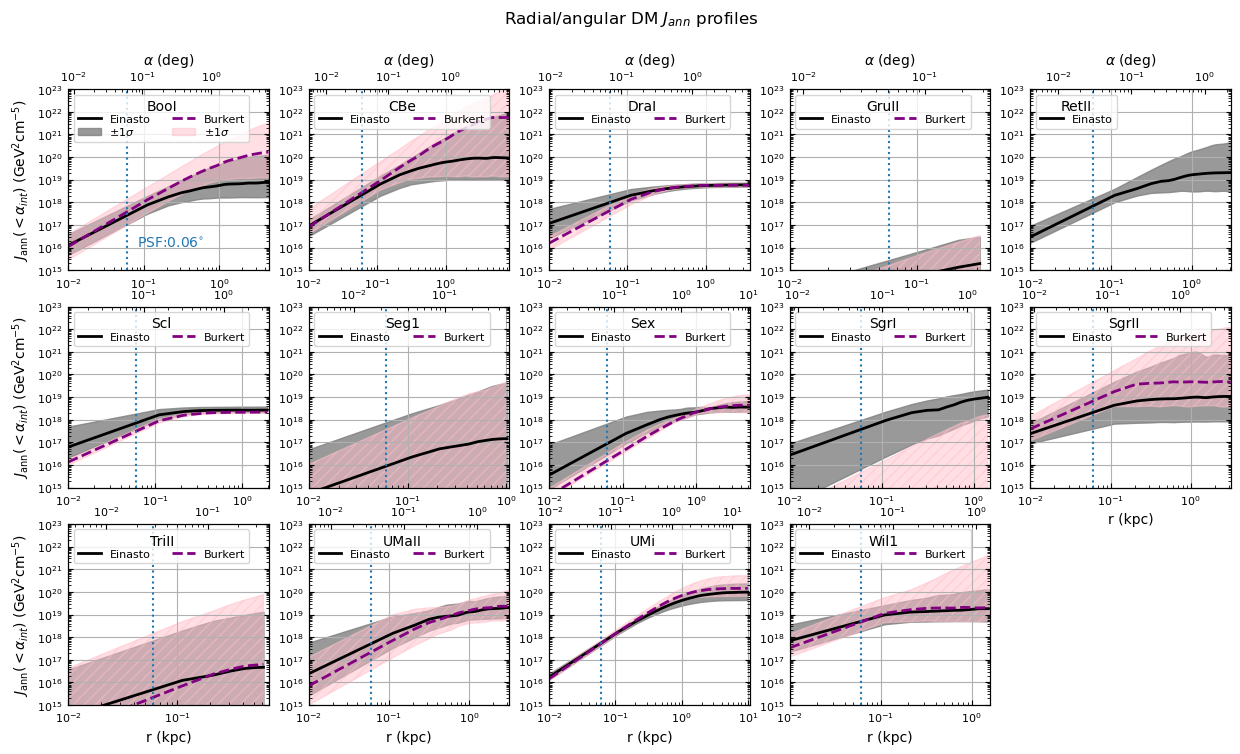

In [42]:
## Version 1

fig, ax_main = plt.subplots(3,5,figsize=(15,8))
fig.suptitle(r"Radial/angular DM $J_{ann}$ profiles")

x_new = np.linspace(0.01,10,100) 

counter = 1
for name, ax in zip(dSphNames, ax_main.flat):
    
    Rt_ein = alpha_Einasto_tidal[counter-1]
    Rt_bur = alpha_Burkert_tidal[counter-1]
    alpha_optimal = alpha_opt[counter-1]
    
    x_cut = x_new[x_new<=Rt_ein]
    r_kpc = distance[counter-1] * np.tan(np.deg2rad(x_cut))
    
    counter = counter + 1

    # Plot the Einasto profiles
    #
    #
    j_inter,j_dw1s,j_up1s = jfactor_inter1d(name=name, profile='Einasto')
 
    ax.plot(x_cut,j_inter(x_cut), linewidth=2, color='black',label="Einasto")

    if name == "BooI":
        ax.fill_between(x_cut,
                        j_up1s(x_cut),
                        j_dw1s(x_cut), color='grey',  label=r"$\pm1\sigma$", alpha=0.8)
    else:
       ax.fill_between(x_cut,
                        j_up1s(x_cut),
                        j_dw1s(x_cut), color='grey', alpha=0.8)
        
    # Plot the Burkert profiles 
    jb_inter,jb_dw1s,jb_up1s = jfactor_inter1d(name=name, profile='Burkert')

    if (name != "RetII"):
        ax.plot(x_cut,jb_inter(x_cut), linewidth=2, linestyle='--', color='purple', label='Burkert')
        if name == "BooI":
            ax.fill_between(x_cut,
                            jb_up1s(x_cut),
                            jb_dw1s(x_cut), color='pink',  label=r"$\pm1\sigma$", alpha=0.5)
        else:
            ax.fill_between(x_cut,
                            jb_up1s(x_cut),
                            jb_dw1s(x_cut), color='pink', alpha=0.5, hatch='///')
        
    # Plot PSF
    ax.axvline(x = 0.06, color = 'tab:blue', linestyle='dotted')
    if name == "BooI":
        ax.text(0.08, 1.1e16, r'PSF:$0.06^{\circ}$', fontsize=10, color='tab:blue')


        
        
    # Compute a 2nd axis with distances instead of angles
    ax2 = ax.twiny()
    ax2.plot(r_kpc,j_inter(x_cut), linewidth=0, color='black',  label='Einasto')
    ax2.loglog()
    


    if (counter-1 == 1 or counter-1 == 6 or counter-1 == 11 ):
        ax.set_ylabel(r"$J_{\rm ann}(<\alpha_{int})$ (GeV$^2$cm$^{-5}$)", fontsize=10)
    
    if counter-1 <= 5:
         ax2.set_xlabel(r"$\alpha$ (deg)", fontsize=10)
    if counter-1 >= 10:
         ax.set_xlabel(r"r (kpc)", fontsize=10)

 # Adjust tick label size and padding
    ax.tick_params(axis='both', which='major', labelsize=8, pad=4)
    ax2.tick_params(axis='both', which='major', labelsize=8, pad=4)

    ax.set_ylim(1e15,1e23)
    ax.set_xlim(1e-2,Rt_ein)
    ax.loglog()
    ax.grid()
    ax.tick_params(which='both', direction='in', top=False, right=True)
    ax2.tick_params(which='both', direction='in', top=True, right=True)

    ax.legend(title=name, fontsize=8, loc='upper left', labelspacing=0.1,ncols=2)


ax_main[-1, -1].axis('off')
ax_main[-1, -1].set_facecolor('white')

  
#plt.savefig('plot_profiles_jfactor_14.png', bbox_inches='tight', pad_inches=0.4)



plt.show()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that 

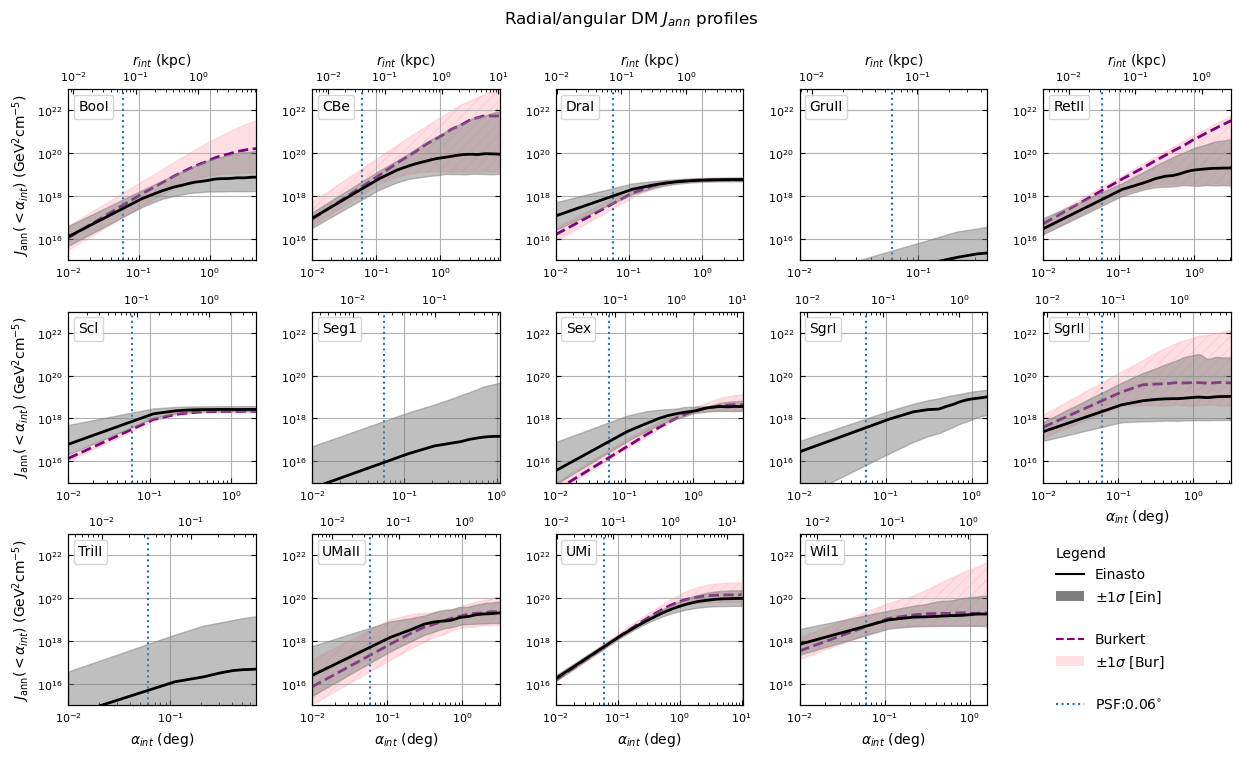

In [45]:
## Version 2 (with legend on last empty pad)

fig, ax_main = plt.subplots(3,5,figsize=(15,8))
fig.suptitle(r"Radial/angular DM $J_{ann}$ profiles")
fig.subplots_adjust(wspace=0.3, hspace=0.3)


x_new = np.linspace(0.01,10,100) 

counter = 1
for name, ax in zip(dSphNames, ax_main.flat):
    
    Rt_ein = alpha_Einasto_tidal[counter-1]
    Rt_bur = alpha_Burkert_tidal[counter-1]
    alpha_optimal = alpha_opt[counter-1]
    
    x_cut = x_new[x_new<=Rt_ein*1.2]
    r_kpc = distance[counter-1] * np.tan(np.deg2rad(x_cut))
    
    counter = counter + 1

    # Plot the Einasto profiles
    #
    #
    j_inter,j_dw1s,j_up1s = jfactor_inter1d(name=name, profile='Einasto')
 
    ax.plot(x_cut,j_inter(x_cut), linewidth=2, color='black', zorder = 4)

    if name == "BooI":
        ax.fill_between(x_cut,
                        j_up1s(x_cut),
                        j_dw1s(x_cut), color='grey', alpha=0.5, zorder = 3)
    else:
       ax.fill_between(x_cut,
                        j_up1s(x_cut),
                        j_dw1s(x_cut), color='grey', alpha=0.5, zorder = 3)
        
    # Plot the Burkert profiles 
    jb_inter,jb_dw1s,jb_up1s = jfactor_inter1d(name=name, profile='Burkert')

    #if (name != "RetII"):
       
#    if (name != "GruII" or name != "Seg1" or name != "TriII" or name != "SgrI"):
    if (name == "BooI" or name == "CBe" or name == "DraI" or name == "RetII" or name == "Scl" or name == "Sex" or name == "SgrII" or name == "UMaII" or name == "UMi" or name == "Wil1"):
        ax.plot(x_cut,jb_inter(x_cut), linewidth=2, linestyle='--', color='purple', zorder = 2)
        if name == "BooI":
            ax.fill_between(x_cut,
                            jb_up1s(x_cut),
                            jb_dw1s(x_cut), color='pink',  alpha=0.5, zorder = 1)
        else:
            ax.fill_between(x_cut,
                            jb_up1s(x_cut),
                            jb_dw1s(x_cut), color='pink', alpha=0.5, hatch='///', zorder = 1)
        
    # Plot PSF
    ax.axvline(x = 0.06, color = 'tab:blue', linestyle='dotted')
    #if name == "BooI":
    #    ax.text(0.08, 1.1e16, r'PSF:$0.06^{\circ}$', fontsize=10, color='tab:blue')


        
        
    # Compute a 2nd axis with distances instead of angles
    ax2 = ax.twiny()
    ax2.plot(r_kpc,j_inter(x_cut), linewidth=0, color='black',  label='Einasto')
    ax2.loglog()
    


    if (counter-1 == 1 or counter-1 == 6 or counter-1 == 11 ):
        ax.set_ylabel(r"$J_{\rm ann}(<\alpha_{int})$ (GeV$^2$cm$^{-5}$)", fontsize=10)
    
    if counter-1 <= 5:
         ax2.set_xlabel(r"$r_{int}$ (kpc)", fontsize=10)
         #ax2.set_xlabel(r"$\alpha$ (deg)", fontsize=10)
    if counter-1 >= 10:
         #ax.set_xlabel(r"r (kpc)", fontsize=10)
         ax.set_xlabel(r"$\alpha_{int}$ (deg)", fontsize=10)

 # Adjust tick label size and padding
    ax.tick_params(axis='both', which='major', labelsize=8, pad=4)
    ax2.tick_params(axis='both', which='major', labelsize=8, pad=4)

    ax.set_ylim(1e15,1e23)
    ax.set_xlim(1e-2,Rt_ein)
    ax.loglog()
    ax.grid()
    ax.tick_params(which='both', direction='in', top=False, right=True)
    ax2.tick_params(which='both', direction='in', top=True, right=True)

    ax.legend(title=name, fontsize=8, loc='upper left', labelspacing=0.1,ncols=2)


ax_main[-1, -1].axis('off')
ax_main[-1, -1].set_facecolor('white')

from matplotlib.lines import Line2D
from matplotlib.patches import Patch


# Use last axis (bottom-right) for the legend
handles = [
    Line2D([0], [0], color='black', label='Einasto'),
    Patch(facecolor='black', alpha=0.5, label=r'$\pm1\sigma$ [Ein]'),   # fascia grigia
    #Line2D([0], [0], color='tab:blue', linestyle='-', label='Tidal Radius [Ein]'),
    Patch(facecolor='white', alpha=0.3),
    Line2D([0], [0], color='purple', linestyle='--', label='Burkert'),
    Patch(facecolor='pink', alpha=0.5, label=r'$\pm1\sigma$ [Bur]' ),   # fascia rosa/viola
    Patch(facecolor='white', alpha=0.3),
    Line2D([0], [0], color='tab:blue', linestyle='dotted', label='PSF:$0.06^{\circ}$'),
]
#ax_main[3, 3].axis('off')  # hide the empty subplot
#ax_main[-1, -1].legend(title="Legend", handles=handles, loc='upper left', frameon=False)

legend = ax_main[-1, -1].legend(title="Legend", handles=handles, loc='upper left', frameon=False)
legend.get_title().set_ha('left')
legend._legend_box.align = "left"  # Optional, aligns content to the left


plt.savefig('plot_profiles_jfactor_14.png', bbox_inches='tight', pad_inches=0.3)



plt.show()

## DM decay Profiles
This part generates the plots for DM Einasto/Burkert decay profile

#### Target name definition 

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that 

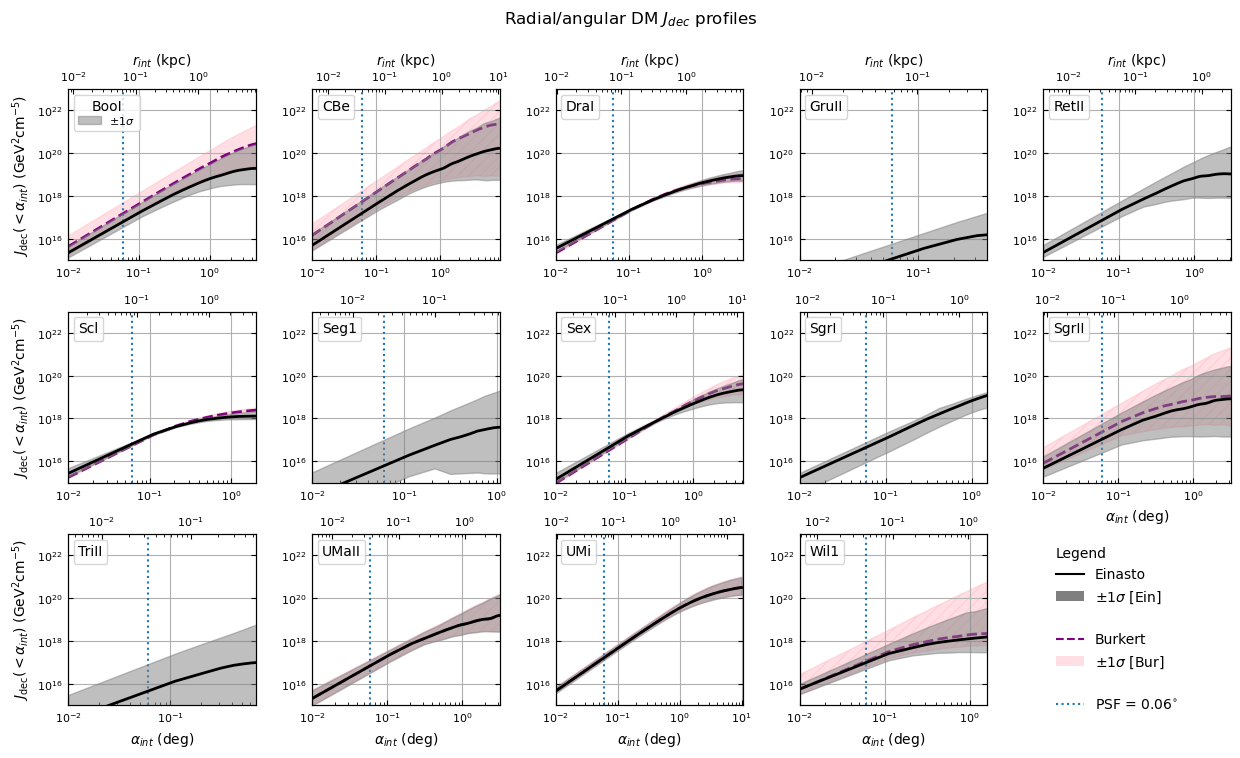

In [47]:
fig, ax_main = plt.subplots(3,5,figsize=(15,8))
fig.suptitle(r"Radial/angular DM $J_{dec}$ profiles")
fig.subplots_adjust(wspace=0.3, hspace=0.3)

x_new = np.linspace(0.01,10,100) 

counter = 1
for name, ax in zip(dSphNames, ax_main.flat):
    
    Rt_ein = alpha_Einasto_tidal[counter-1]
    Rt_bur = alpha_Burkert_tidal[counter-1]
    alpha_optimal = alpha_opt[counter-1]
    
    x_cut = x_new[x_new<=Rt_ein*1.2]
    r_kpc = distance[counter-1] * np.tan(np.deg2rad(x_cut))
    
    counter = counter + 1

    # Plot the Einasto profiles
    #
    #
    d_inter,d_dw1s,d_up1s = dfactor_inter1d(name=name, profile='Einasto')
 
    ax.plot(x_cut,d_inter(x_cut), linewidth=2, color='black', zorder=4)

    if name == "BooI":
        ax.fill_between(x_cut,
                        d_up1s(x_cut),
                        d_dw1s(x_cut), color='grey',  label=r"$\pm1\sigma$", alpha=0.5, zorder=3)
    else:
       ax.fill_between(x_cut,
                        d_up1s(x_cut),
                        d_dw1s(x_cut), color='grey', alpha=0.5, zorder=3)
        
    # Plot the Burkert profiles 
    db_inter,db_dw1s,db_up1s = dfactor_inter1d(name=name, profile='Burkert')

    # if (name != "RetII"):
    if (name == "BooI" or name == "CBe" or name == "DraI" or name == "Scl" or name == "Sex" or name == "SgrII" or name == "UMaII" or name == "UMi" or name == "Wil1"):    
        ax.plot(x_cut,db_inter(x_cut), linewidth=2, linestyle='--', color='purple', zorder=2)
        if name == "BooI":
            ax.fill_between(x_cut,
                            db_up1s(x_cut),
                            db_dw1s(x_cut), color='pink',  alpha=0.5, zorder=1)
        else:
            ax.fill_between(x_cut,
                            db_up1s(x_cut),
                            db_dw1s(x_cut), color='pink', alpha=0.5, hatch='///', zorder=1)
        
    # Plot PSF
    ax.axvline(x = 0.06, color = 'tab:blue', linestyle='dotted')
    #if name == "BooI":
    #    ax.text(0.08, 1.1e16, r'PSF:$0.06^{\circ}$', fontsize=10, color='tab:blue')


        
        
    # Compute a 2nd axis with distances instead of angles
    ax2 = ax.twiny()
    ax2.plot(r_kpc,d_inter(x_cut), linewidth=0, color='black',  label='Einasto')
    ax2.loglog()
    


    if (counter-1 == 1 or counter-1 == 6 or counter-1 == 11 ):
        ax.set_ylabel(r"$J_{\rm dec}(<\alpha_{int})$ (GeV$^2$cm$^{-5}$)", fontsize=10)
    
    if counter-1 <= 5:
         ax2.set_xlabel(r"$r_{int}$ (kpc)", fontsize=10)
         #ax2.set_xlabel(r"$\alpha$ (deg)", fontsize=10)
    if counter-1 >= 10:
         #ax.set_xlabel(r"r (kpc)", fontsize=10)
         ax.set_xlabel(r"$\alpha_{int}$ (deg)", fontsize=10)

 # Adjust tick label size and padding
    ax.tick_params(axis='both', which='major', labelsize=8, pad=4)
    ax2.tick_params(axis='both', which='major', labelsize=8, pad=4)

    ax.set_ylim(1e15,1e23)
    ax.set_xlim(1e-2,Rt_ein)
    ax.loglog()
    ax.grid()
    ax.tick_params(which='both', direction='in', top=False, right=True)
    ax2.tick_params(which='both', direction='in', top=True, right=True)

    ax.legend(title=name, fontsize=8, loc='upper left', labelspacing=0.1,ncols=2)


ax_main[-1, -1].axis('off')
ax_main[-1, -1].set_facecolor('white')

from matplotlib.lines import Line2D
from matplotlib.patches import Patch


# Use last axis (bottom-right) for the legend
handles = [
    Line2D([0], [0], color='black', label='Einasto'),
    Patch(facecolor='black', alpha=0.5, label=r'$\pm1\sigma$ [Ein]'),   # fascia grigia
    #Line2D([0], [0], color='tab:blue', linestyle='-', label='Tidal Radius [Ein]'),
    Patch(facecolor='white', alpha=0.3),
    Line2D([0], [0], color='purple', linestyle='--', label='Burkert'),
    Patch(facecolor='pink', alpha=0.5, label=r'$\pm1\sigma$ [Bur]' ),   # fascia rosa/viola
    Patch(facecolor='white', alpha=0.3),
    Line2D([0], [0], color='tab:blue', linestyle='dotted', label='PSF = $0.06^{\circ}$'),
]
#ax_main[3, 3].axis('off')  # hide the empty subplot
#ax_main[-1, -1].legend(title="Legend", handles=handles, loc='upper left', frameon=False)

legend = ax_main[-1, -1].legend(title="Legend", handles=handles, loc='upper left', frameon=False)
legend.get_title().set_ha('left')
legend._legend_box.align = "left"  # Optional, aligns content to the left
    
plt.savefig('plot_profiles_dfactor_14.png', bbox_inches='tight', pad_inches=0.3)



plt.show()